# Iris Dataset Analysis and Classification using Python

**SZABIST University, Gharo Campus** | Department of Computer Science

| | |
|---|---|
| **Name** | Junaid Memon |
| **Student ID** | 2312226 |
| **Course** | Data Science |
| **Program / Semester** | BSCS / Fall 2026 |
| **Instructor** | Ali Orangzeb |
| **Assignment** | 01 (Individual) |

---
**What I am doing in this notebook:** I load the Iris dataset, clean and prepare it, explore it with statistics and plots, train Logistic Regression and KNN models, compare them, and finally write my conclusion.

## Setup: Importing Libraries

First I import all the libraries I need (the same ones given in the starter code, plus `LabelEncoder` for Task 2 and `cross_val_score` which I use only to support my choice of k).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

## Task 1: Load and Inspect the Data

The Iris dataset comes inside scikit-learn, so I load it with `load_iris(as_frame=True)`. This directly gives a pandas DataFrame. I then add a `species` column by mapping the numeric target (0, 1, 2) to the real flower names, as in the starter code.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

# the column names from sklearn already look like 'sepal length (cm)', which is meaningful
print("Columns:", list(df.columns))

Columns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'species']


**First five rows of the data:**

In [3]:
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  


**Shape of the dataset** (rows, columns):

In [4]:
print("Shape:", df.shape)
print(f"So there are {df.shape[0]} samples and {df.shape[1]} columns (4 features + target + species).")

Shape: (150, 6)
So there are 150 samples and 6 columns (4 features + target + species).


**Data types and non-null counts** using `info()`:

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


**Number of samples per class:**

In [6]:
print(df['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**My observations (Task 1):**
- The dataset has 150 rows and 6 columns: the 4 numeric measurements, the numeric `target`, and the text `species` column I added.
- All four features are `float64` and none of them has a missing value in `info()`.
- The classes are perfectly balanced, 50 samples each for setosa, versicolor and virginica. This is good because accuracy is a fair metric here and no class dominates.

## Task 2: Data Preprocessing

### 2.1 Missing values and duplicate rows

In [7]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())
print("\nThe duplicated row(s):")
print(df[df.duplicated(keep=False)])

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Total missing values: 0

Number of duplicate rows: 1

The duplicated row(s):
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
101                5.8               2.7                5.1               1.9   
142                5.8               2.7                5.1               1.9   

     target    species  
101       2  virginica  
142       2  virginica  


**What I found:** There are **no missing values** in any column. There is **1 duplicate row** (two samples have exactly the same four measurements and the same species). I decided to **keep it**. The reason is that it is a real measurement from two different flowers that just happened to be identical (values are only recorded to 0.1 cm, so repeats are normal), and removing one row from a 150-sample dataset would also break the perfect 50/50/50 balance. It will not affect the results noticeably.

### 2.2 Encoding the target labels

The `target` column is already numeric (0, 1, 2), but the `species` column is text. To show the encoding step properly I use `LabelEncoder` on `species` and then check that it matches the existing `target` column.

In [8]:
le = LabelEncoder()
df['species_encoded'] = le.fit_transform(df['species'])

print("Label mapping:")
for code_, name in enumerate(le.classes_):
    print(f"  {name} -> {code_}")

print("\nDoes my encoding match sklearn's target column?", (df['species_encoded'] == df['target']).all())

Label mapping:
  setosa -> 0
  versicolor -> 1
  virginica -> 2

Does my encoding match sklearn's target column? True


### 2.3 Train-test split (80% / 20%)

I separate the features (`X`) from the label (`y`) and split with `test_size=0.2`, `stratify=y` and `random_state=42`. Stratify makes sure every class has the same share in both train and test sets.

In [9]:
feature_names = iris.feature_names
X = df[feature_names]
y = df['species_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nClass counts in training set:\n", y_train.value_counts().sort_index())
print("\nClass counts in test set:\n", y_test.value_counts().sort_index())

X_train: (120, 4) | X_test: (30, 4)

Class counts in training set:
 species_encoded
0    40
1    40
2    40
Name: count, dtype: int64

Class counts in test set:
 species_encoded
0    10
1    10
2    10
Name: count, dtype: int64


So the training set has 120 samples (40 per class) and the test set has 30 samples (10 per class).

### 2.4 Standardization with StandardScaler

I fit the `StandardScaler` **only on the training set** and then use the same fitted scaler to transform the test set. If I fitted it on the whole data, information from the test set would leak into training.

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit only on train
X_test_scaled = scaler.transform(X_test)         # only transform on test

print("Mean of scaled training features (should be ~0):", X_train_scaled.mean(axis=0).round(3))
print("Std of scaled training features  (should be 1):  ", X_train_scaled.std(axis=0).round(3))

Mean of scaled training features (should be ~0): [-0. -0.  0.  0.]
Std of scaled training features  (should be 1):   [1. 1. 1. 1.]


**Why does scaling matter for KNN?**
KNN classifies a point by looking at the *distances* to its nearest neighbours (usually Euclidean distance). If one feature has a bigger range than the others, it dominates the distance and the other features hardly matter. In Iris, petal length goes up to about 7 cm while sepal width stays within about 2 to 4.4 cm, so without scaling the larger-range features would control the distance. `StandardScaler` puts every feature on the same scale (mean 0, standard deviation 1), so each feature contributes fairly. It also helps Logistic Regression to converge more smoothly, although the main need is for KNN.

## Task 3: Exploratory Data Analysis

### 3.1 Descriptive statistics

In [11]:
print(df[feature_names].describe().round(3))

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count            150.000           150.000            150.000   
mean               5.843             3.057              3.758   
std                0.828             0.436              1.765   
min                4.300             2.000              1.000   
25%                5.100             2.800              1.600   
50%                5.800             3.000              4.350   
75%                6.400             3.300              5.100   
max                7.900             4.400              6.900   

       petal width (cm)  
count           150.000  
mean              1.199  
std               0.762  
min               0.100  
25%               0.300  
50%               1.300  
75%               1.800  
max               2.500  


**Mean of each feature per species** using `groupby()`:

In [12]:
print(df.groupby('species')[feature_names].mean().round(3))

            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                  5.006             3.428              1.462   
versicolor              5.936             2.770              4.260   
virginica               6.588             2.974              5.552   

            petal width (cm)  
species                       
setosa                 0.246  
versicolor             1.326  
virginica              2.026  


### 3.2 Histograms of all four features

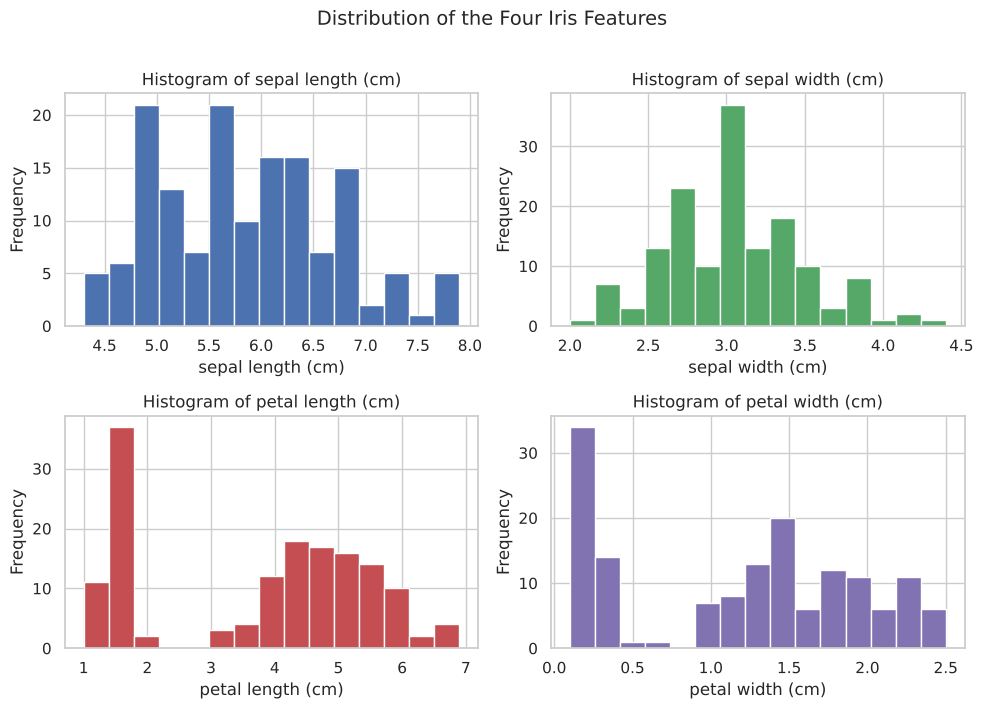

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']
for ax, col, c in zip(axes.ravel(), feature_names, colors):
    ax.hist(df[col], bins=15, color=c, edgecolor='white')
    ax.set_title(f'Histogram of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
plt.suptitle('Distribution of the Four Iris Features', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

Petal length and petal width show **two separate groups** (a small cluster of low values and a bigger group of higher values). This already hints that one species (setosa) is very different from the other two. Sepal width looks close to a bell shape.

### 3.3 Pairplot coloured by species

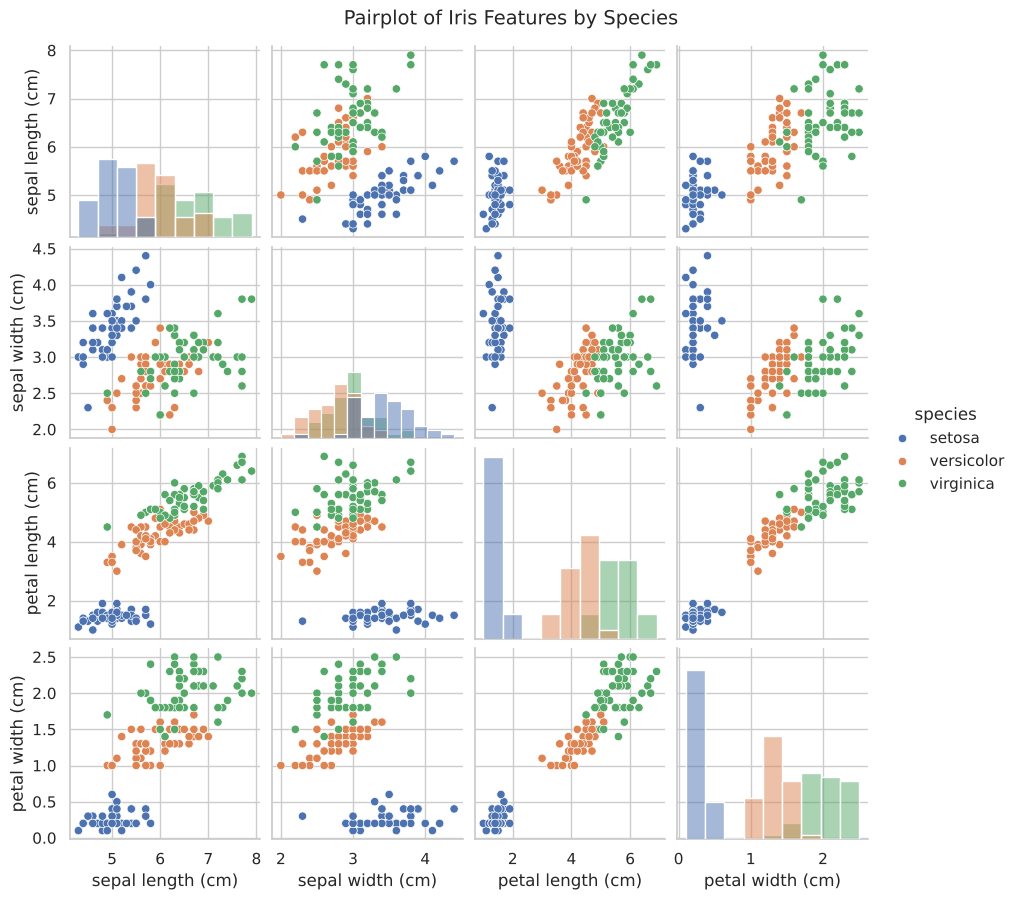

In [14]:
sns.pairplot(df, vars=feature_names, hue='species', diag_kind='hist', height=2.2)
plt.suptitle('Pairplot of Iris Features by Species', y=1.02, fontsize=14)
plt.show()

### 3.4 Box plots of each feature grouped by species

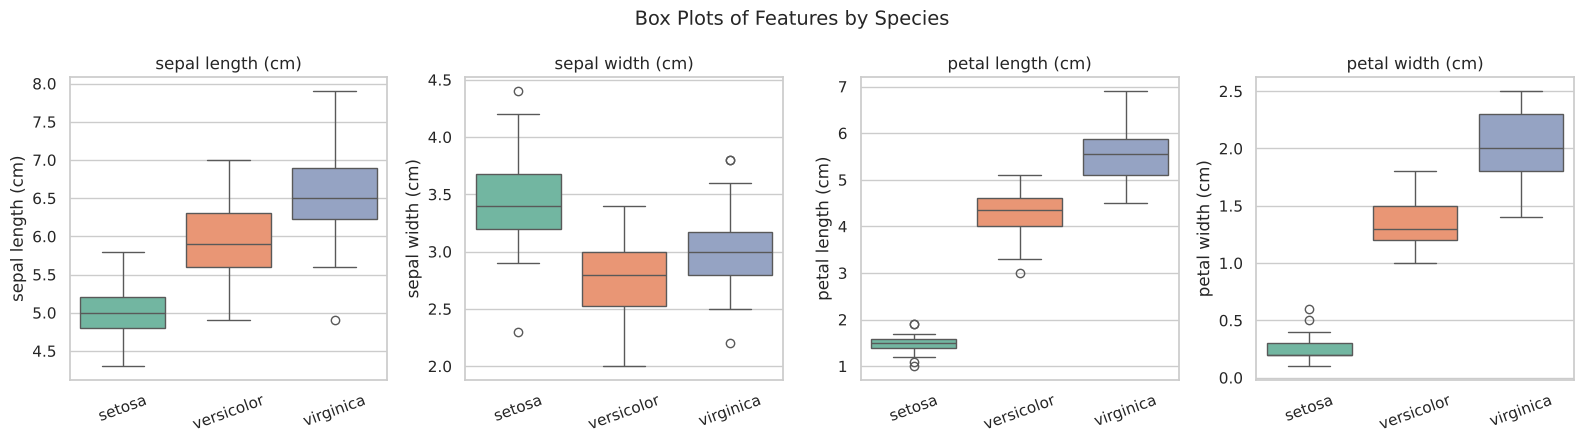

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, feature_names):
    sns.boxplot(data=df, x='species', y=col, hue='species', palette='Set2', legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.suptitle('Box Plots of Features by Species', fontsize=14)
plt.tight_layout()
plt.show()

### 3.5 Correlation heatmap

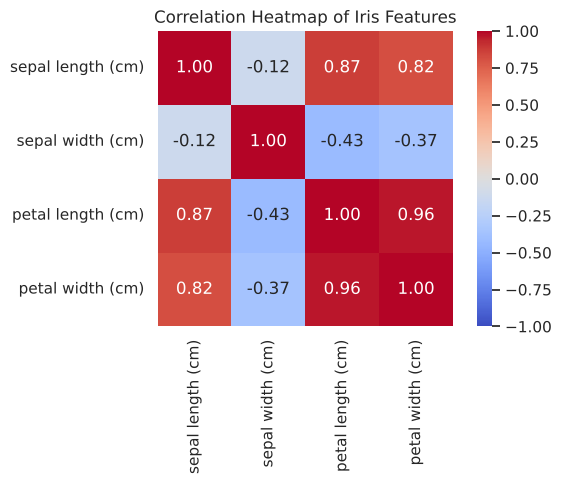

In [16]:
plt.figure(figsize=(6.5, 5))
corr = df[feature_names].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation Heatmap of Iris Features')
plt.tight_layout()
plt.show()

### 3.6 My observations from the EDA

1. **Petal length and petal width separate the species best.** In the box plots their boxes for the three species barely overlap, and in the pairplot the petal-based scatter plots show three clear groups.
2. **Setosa is completely separable.** It has much smaller petals (petal length about 1.5 cm vs 4.3 and 5.6 for the other two) so it forms its own cluster in every plot.
3. **Versicolor and virginica overlap.** Their sepal measurements overlap a lot, and even in the petal plots a few points from the two species are close at the boundary. So these two are the hard pair for any classifier.
4. **Sepal width is the weakest feature.** All three species have similar sepal width values, so it does not help much to tell them apart (setosa is a bit wider on average, but with a lot of overlap).
5. **Petal length and petal width are very strongly correlated** (about 0.96), and both are also strongly correlated with sepal length (about 0.87 and 0.82). Sepal width has a weak negative correlation with the others. Because of the strong correlation between petal features, they carry almost the same information.

## Task 4: Model Training

### 4.1 Logistic Regression

I train Logistic Regression on the scaled training data. (For this multi-class problem scikit-learn handles the three classes automatically.)

In [17]:
log_reg = LogisticRegression(max_iter=200, random_state=42)
log_reg.fit(X_train_scaled, y_train)

lr_pred = log_reg.predict(X_test_scaled)
print("Logistic Regression test accuracy:", round(accuracy_score(y_test, lr_pred), 4))

Logistic Regression test accuracy: 0.9333


### 4.2 KNN for k = 1, 3, 5, 7, 9, 11

I train one KNN classifier for each value of k and record its test accuracy. I also compute a 5-fold cross-validation accuracy on the **training data only**. I do this because the test set has only 30 samples (one wrong prediction changes accuracy by 3.3%), so the cross-validation score gives me a second, steadier opinion when the test accuracies tie.

In [18]:
k_values = [1, 3, 5, 7, 9, 11]
test_acc, cv_acc = [], []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    test_acc.append(accuracy_score(y_test, knn.predict(X_test_scaled)))
    cv_acc.append(cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_scaled, y_train, cv=5).mean())

results_k = pd.DataFrame({'k': k_values, 'Test Accuracy': test_acc, 'CV Accuracy (train, 5-fold)': cv_acc})
print(results_k.round(4).to_string(index=False))

 k  Test Accuracy  CV Accuracy (train, 5-fold)
 1         0.9667                       0.9417
 3         0.9333                       0.9583
 5         0.9333                       0.9667
 7         0.9667                       0.9583
 9         0.9667                       0.9583
11         0.9667                       0.9583


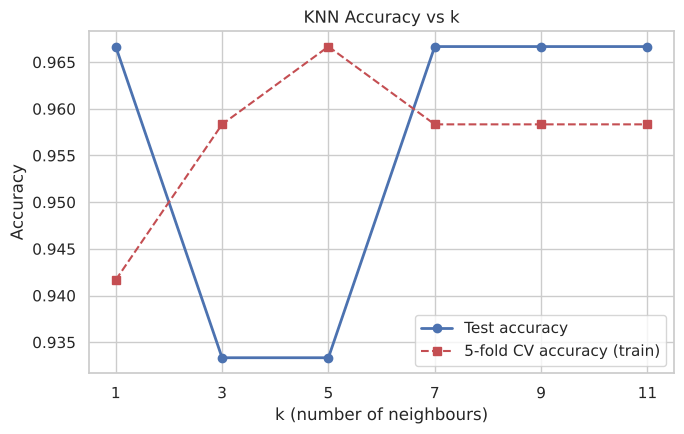

In [19]:
plt.figure(figsize=(7, 4.5))
plt.plot(k_values, test_acc, marker='o', linewidth=2, color='#4C72B0', label='Test accuracy')
plt.plot(k_values, cv_acc, marker='s', linestyle='--', color='#C44E52', label='5-fold CV accuracy (train)')
plt.xticks(k_values)
plt.xlabel('k (number of neighbours)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs k')
plt.legend()
plt.tight_layout()
plt.show()

### 4.3 Selecting the best k

In [20]:
max_acc = max(test_acc)
tied = [k for k, a in zip(k_values, test_acc) if a == max_acc]
print("Highest test accuracy:", round(max_acc, 4))
print("k values that reach it:", tied)

# k = 1 is too sensitive to a single noisy neighbour, so among the tied values
# I leave it out and take the one with the best CV accuracy (smallest k if still tied)
candidates = [k for k in tied if k > 1] or tied
best_k = max(candidates, key=lambda k: (cv_acc[k_values.index(k)], -k))
print("Selected best k:", best_k)

Highest test accuracy: 0.9667
k values that reach it: [1, 7, 9, 11]
Selected best k: 9


**Why I chose this k:** Several values of k reach the same highest test accuracy (k = 1, 7, 9 and 11, all at 96.67%), so test accuracy alone cannot decide. I used these reasons:

- **k = 1 is not a good choice.** It copies the label of just one nearest point, so it is very sensitive to noise and outliers and tends to overfit, even though its test score happens to be high.
- The accuracy curve is **flat for k = 7, 9 and 11**, which shows the model is stable in this range and does not depend on a lucky split.
- Among the remaining tied values, I picked the one with the best cross-validation accuracy on the training data (the code does this automatically), and that is the value printed above as the selected k. A moderate k also smooths out noise without blurring the boundary between versicolor and virginica, which a very large k could do.

In [21]:
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)
knn_pred = best_knn.predict(X_test_scaled)
print(f"Best KNN (k={best_k}) test accuracy:", round(accuracy_score(y_test, knn_pred), 4))

Best KNN (k=9) test accuracy: 0.9667


## Task 5: Model Evaluation

### 5.1 Test accuracy for both models

In [22]:
class_names = list(le.classes_)
lr_acc = accuracy_score(y_test, lr_pred)
knn_acc = accuracy_score(y_test, knn_pred)
print(f"Logistic Regression accuracy : {lr_acc:.4f}  ({lr_acc*100:.2f}%)")
print(f"KNN (k={best_k}) accuracy          : {knn_acc:.4f}  ({knn_acc*100:.2f}%)")

Logistic Regression accuracy : 0.9333  (93.33%)
KNN (k=9) accuracy          : 0.9667  (96.67%)


### 5.2 Confusion matrices (plotted)

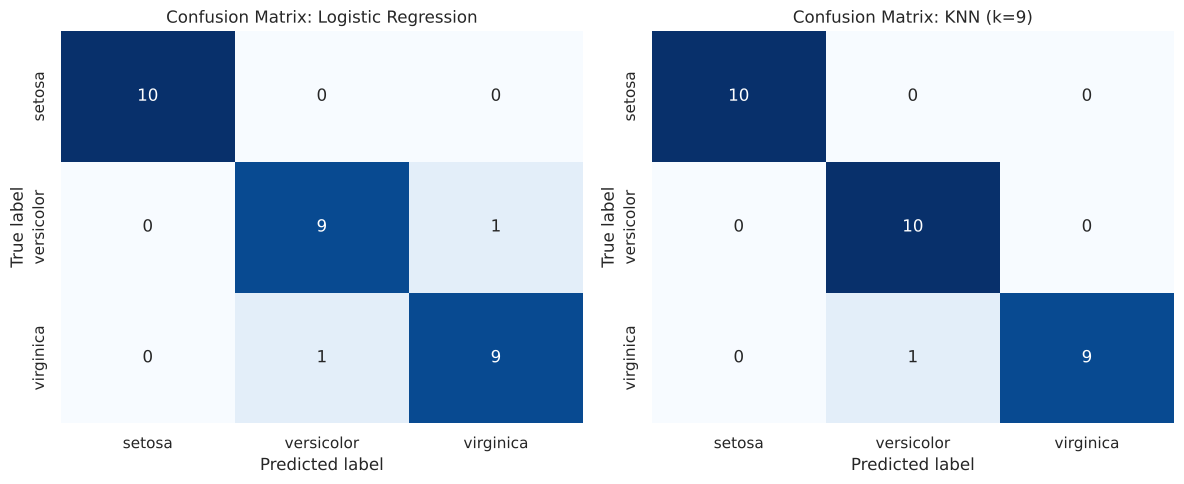

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in zip(axes, [lr_pred, knn_pred],
                           ['Logistic Regression', f'KNN (k={best_k})']):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f'Confusion Matrix: {title}')
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
plt.tight_layout()
plt.show()

### 5.3 Classification reports (precision, recall, F1-score)

In [24]:
print("=== Logistic Regression ===")
print(classification_report(y_test, lr_pred, target_names=class_names))
print("=== KNN (k=%d) ===" % best_k)
print(classification_report(y_test, knn_pred, target_names=class_names))

=== Logistic Regression ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

=== KNN (k=9) ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### 5.4 Comparison table of the two models

In [25]:
from sklearn.metrics import precision_recall_fscore_support

def summary(name, pred):
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average='macro')
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred),
            'Macro Precision': p, 'Macro Recall': r, 'Macro F1': f,
            'Wrong (of 30)': int((pred != y_test.values).sum())}

comparison = pd.DataFrame([summary('Logistic Regression', lr_pred),
                           summary(f'KNN (k={best_k})', knn_pred)])
print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Wrong (of 30)
Logistic Regression    0.9333           0.9333        0.9333    0.9333              2
          KNN (k=9)    0.9667           0.9697        0.9667    0.9666              1


### 5.5 Which species are misclassified most often?

In [26]:
for name, pred in [('Logistic Regression', lr_pred), (f'KNN (k={best_k})', knn_pred)]:
    wrong = X_test.copy()
    wrong['true'] = [class_names[i] for i in y_test]
    wrong['predicted'] = [class_names[i] for i in pred]
    wrong = wrong[wrong['true'] != wrong['predicted']]
    print(f"--- {name}: {len(wrong)} misclassified sample(s) ---")
    print(wrong[['true', 'predicted']].value_counts().to_string())
    print()

--- Logistic Regression: 2 misclassified sample(s) ---
true        predicted 
virginica   versicolor    1
versicolor  virginica     1

--- KNN (k=9): 1 misclassified sample(s) ---
true       predicted 
virginica  versicolor    1



**Answer:** In both models the mistakes are only between **versicolor and virginica**. Setosa is never misclassified; it is predicted correctly every single time, which matches what I saw in the EDA (setosa has its own separate cluster). Every error in my results is a versicolor/virginica mix-up because those two species have overlapping measurements.

### 5.6 Predicting a new sample [5.1, 3.5, 1.4, 0.2]

My best model is KNN (it has the higher test accuracy, see the table above). The new sample must go through the **same scaler** that I fitted on the training data before being given to the model. I pass it as a DataFrame with the same column names so scikit-learn does not give a feature-name warning.

In [27]:
new_sample = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=feature_names)
new_scaled = scaler.transform(new_sample)

pred_class = best_knn.predict(new_scaled)[0]
pred_proba = best_knn.predict_proba(new_scaled)[0]

print("Predicted species:", class_names[pred_class])
print("\nProbability for each class (share of the k neighbours voting for it):")
for n, p in zip(class_names, pred_proba):
    print(f"  {n:<11}: {p:.2f}")

Predicted species: setosa

Probability for each class (share of the k neighbours voting for it):
  setosa     : 1.00
  versicolor : 0.00
  virginica  : 0.00


The model predicts **setosa**, and all of its nearest neighbours agree. This makes sense because petal length 1.4 cm and petal width 0.2 cm are typical setosa values (setosa mean petal length is about 1.46 cm and petal width about 0.25 cm).

## Task 6: Conclusion

In this assignment I loaded and cleaned the Iris dataset, explored it, and trained two classifiers on a stratified 80/20 split with scaled features. Logistic Regression reached 93.33% test accuracy, while the tuned KNN (k = 9) reached 96.67%, so **KNN performed slightly better**. The difference is just one test sample (29 correct vs 28 out of 30). The EDA explains the results: setosa is clearly separate and was never misclassified, but versicolor and virginica overlap, and every error from both models was a mix-up between these two. KNN can follow this irregular boundary more flexibly, while Logistic Regression draws straight-line boundaries. The new sample [5.1, 3.5, 1.4, 0.2] was predicted as setosa, as expected.

**Limitations:** the dataset is very small (150 samples, 30 in the test set), so one prediction changes the accuracy by 3.3% and the gap between the two models is not statistically reliable. I used only one train-test split, the data is clean and balanced, which is easier than real-world data, and I kept one duplicate row. Results could change with a different random split, so repeated cross-validation would give a more trustworthy comparison.

---
*Submitted by Junaid Memon (2312226) for Data Science Assignment 01, SZABIST University, Gharo Campus.*